<a href="https://colab.research.google.com/github/varshayinithangaraju30-lgtm/customer-segmentation-kmeans/blob/main/performance_testing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 Rows  Scaling (s)  KMeans (s)  Silhouette (s)  Total (s)  Peak memory (MB)
   20       0.0075      0.1800          0.0067     0.1941              0.71
  200       0.0070      0.0402          0.0078     0.0549              0.63
 2000       0.0067      0.0714          0.1194     0.1975             61.13
20000       0.0106      0.2733          0.1158     0.3996             61.61


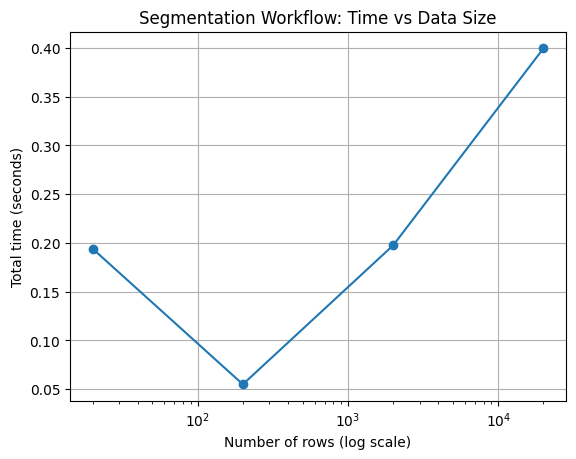

PASS: test_small_data_fast
PASS: test_large_data_under_limit
PASS: test_memory_under_limit


In [1]:

import time
import tracemalloc
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

URL = "https://raw.githubusercontent.com/varshayinithangaraju30-lgtm/customer-segmentation-kmeans/main/Mall_Customers.csv"
FEATURES = ["Age", "Annual Income (k$)", "Spending Score (1-100)"]

base = pd.read_csv(URL).drop_duplicates().dropna(subset=FEATURES)

def make_data(n_rows):
    """Make a bigger dataset by resampling rows and adding small noise."""
    rng = np.random.default_rng(42)
    data = base[FEATURES].sample(n_rows, replace=True, random_state=42).reset_index(drop=True)
    noise = rng.normal(0, 1, size=data.shape)
    return data + noise

def run_workflow(data, k=3):
    t0 = time.perf_counter()
    X = StandardScaler().fit_transform(data)
    t_scale = time.perf_counter() - t0

    t0 = time.perf_counter()
    labels = KMeans(n_clusters=k, init="k-means++", n_init=10, random_state=42).fit_predict(X)
    t_kmeans = time.perf_counter() - t0

    t0 = time.perf_counter()
    sample = min(len(X), 2000)
    silhouette_score(X[:sample], labels[:sample])
    t_metric = time.perf_counter() - t0

    return t_scale, t_kmeans, t_metric

sizes = [20, 200, 2000, 20000]
rows = []
for n in sizes:
    data = make_data(n)
    tracemalloc.start()
    t_scale, t_kmeans, t_metric = run_workflow(data)
    _, peak = tracemalloc.get_traced_memory()
    tracemalloc.stop()
    rows.append({
        "Rows": n,
        "Scaling (s)": round(t_scale, 4),
        "KMeans (s)": round(t_kmeans, 4),
        "Silhouette (s)": round(t_metric, 4),
        "Total (s)": round(t_scale + t_kmeans + t_metric, 4),
        "Peak memory (MB)": round(peak / 1024 / 1024, 2),
    })

perf = pd.DataFrame(rows)
print(perf.to_string(index=False))

plt.plot(perf["Rows"], perf["Total (s)"], marker="o")
plt.xscale("log")
plt.xlabel("Number of rows (log scale)")
plt.ylabel("Total time (seconds)")
plt.title("Segmentation Workflow: Time vs Data Size")
plt.grid(True)
plt.show()

# ---------- Performance tests ----------
def test_small_data_fast():
    assert perf.loc[perf["Rows"] == 200, "Total (s)"].iloc[0] < 5

def test_large_data_under_limit():
    assert perf.loc[perf["Rows"] == 20000, "Total (s)"].iloc[0] < 30

def test_memory_under_limit():
    assert perf["Peak memory (MB)"].max() < 500

for t in [test_small_data_fast, test_large_data_under_limit, test_memory_under_limit]:
    try:
        t()
        print("PASS:", t.__name__)
    except AssertionError:
        print("FAIL:", t.__name__)